In [24]:
import numpy as np
import matplotlib.pyplot as plt 

In [2]:
scores = np.array([67, 82, 10, 10])

In [3]:
print(min(scores))
print(max(scores))
print(sum(scores)/len(scores))

10
82
42.25


In [4]:
print(scores.shape)

(4,)


In [5]:
print(np.sum(scores))
print(np.mean(scores))

169
42.25


## The differences between a NumPy ndarray and a nested list in Python

### Nested list

> The following shows how a nested list would be made in standard python

In [ ]:
nested_list_py = [["red","blue","green","pink"], ["cats", "dogs", "fish", "snakes"]]
print(nested_list_py)

[['red', 'blue', 'green', 'pink'], ['cats', 'dogs', 'fish', 'snakes']]


## NumPy ndarray

> now heres the same thing as a NumPy ndarray

In [5]:
nested_array_np = np.array([["red","blue","green","pink"],["cats", "dogs", "fish", "snakes"]])
print(nested_array_np)

[['red' 'blue' 'green' 'pink']
 ['cats' 'dogs' 'fish' 'snakes']]


## Compareing the speed of python and num py when preforming square operations

### Methoids:

> python has 2 ways of preforming sqr operations, `x ** 2` and `x * x`
> numpy has 1 way: `np.square(arr)`

In [15]:
# random array of numbers: 
# random number generateior
rng = np.random.default_rng()

# Generate a array of random integers from 1 to 100 with 1000 rows and 10 colloms
arr = rng.integers(low=1, high=101, size=(1000, 10))

# makeing more arrays for task 3. key:
# arr = 1,000 rows
# arr1 = 10,000 rows
# arr2 = 100,000 rows
# arr3 = 1,000,000 rows
# i am NOT trying 10,000,000 rows (100,000,000 elements) like hes telling me to

arr1 = rng.integers(low=1, high=101, size=(10000, 10))
arr2 = rng.integers(low=1, high=101, size=(100000, 10))
arr3 = rng.integers(low=1, high=101, size=(1000000, 10))

> now that the array rng is done, i need to do:
```
Task 1: Plain Python: Write a function that uses traditional nested for loops to visit each element of the array and apply your group's function to it (use ndarray.shape to get the number of rows and columns). Use the math module, not NumPy, inside the loop.
```
> because im doing square, and python has 2 ways of doing this (`x ** 2` and `x * x`) i need to make 2 functions

In [10]:
# creating the python functions

# Python Method 1: x ** 2
def square_power(array):
    rows, cols = array.shape
    result = []
    for r in range(rows):
        row_result = []
        for c in range(cols):
            x = int(array[r, c]) # Convert to plain Python int so we aren't using NumPy math
            row_result.append(x ** 2)
        result.append(row_result)
    return result

# Python Method 2: x * x
def square_multiply(array):
    rows, cols = array.shape
    result = []
    for r in range(rows):
        row_result = []
        for c in range(cols):
            x = int(array[r, c])
            row_result.append(x * x)
        result.append(row_result)
    return result

# numpy doesnt need a function that loops through because it can accept arrarys by default: `np.square(arr)`

### Timeing the exicutions:

I will use the `%timeit` function of jypitor notebook.

1. python sqr power: `x ** 2` (sqr_power)
2. python sqr multi: `x * x` (sqr_multi)
3. numpy sqr: `np.square(arr)` (sqr_numpy)

`%%timeit -v {varible}` is easyer for me then `%%timeit -o` and then catching the output in the next cell

In [16]:
%%timeit -v sqr_power
square_power(arr)

2.15 ms ± 235 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [19]:
%%timeit -v sqr_multi
square_multiply(arr)

1.72 ms ± 88.9 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [21]:
%%timeit -v sqr_numpy
np.square(arr)

3.28 μs ± 101 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [ ]:
# prints the mean execution time across all runs in seconds for each function

print(sqr_power.average)
print(sqr_multi.average)

# the avrage is recorded as `3.2760805971546298e-06` witch equils `0.00000328 μ seconds`
print(sqr_numpy.average)

0.002149451465857315
0.00172120632671327
3.2760805971546298e-06


I gotta check in with chris because it looks like numpy took more then 3 times as long as everything else witch doesnt sound right. 

nvm i found the issue, the 2 python functions are timed as `ms ± μs` (miliseconds ± microseconds) while the numpy function is timed as `μs ± ns` (microseconds ± nanoseconds)

So the python functions take `thousandths of a second` with `one-millionths of a second` margen for error
while the numpy function takes `one-millionths of a second` with `one-billionths of a second` margen for error

so the numpy fuction can run in the margen of error of the recored python function exicution time 

## Histrogram comparing the 3 fuctions on an array with 10,000 elements

histogram useing the matplot library.

- x = methoid
- y = time (ms)

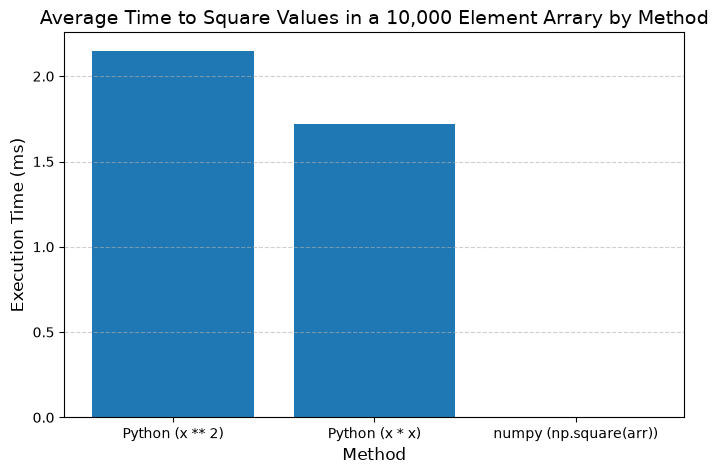

In [27]:

methods = ['Python (x ** 2)', 'Python (x * x)', 'numpy (np.square(arr))']

# converting the times from seconds to ms
times_ms = [
    sqr_power.average * 1000,
    sqr_multi.average * 1000,
    sqr_numpy.average * 1000
]

# makeing the bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(methods, times_ms)

# Lablels
plt.xlabel('Method', fontsize=12)
plt.ylabel('Execution Time (ms)', fontsize=12)
plt.title('Average Time to Square Values in a 10,000 Element Arrary by Method', fontsize=14)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()
